In [1]:
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.config import *
from src.utils import *
from src.experiments import run_experiment, run_ensembles, show, oof_predictions

In [2]:
train = pd.read_csv(BINARY_FEATURES_TRAIN_CSV)
feature_cols = [c for c in train.columns if c not in ("filename", "label")]
X, y = train[feature_cols].values, train["label"].values
print(X.shape, np.bincount(y))

(5170, 230) [2500 2670]


In [3]:
BASE = ["SVM (RBF)", "XGBoost", "CatBoost", "HistGradBoost"]
table_base, fitted_base = run_experiment("E0 all features", X, y, only=BASE)
show(table_base)

[E0 all features] HistGradBoost: balanced_accuracy = 0.847
[E0 all features] SVM (RBF): balanced_accuracy = 0.858
[E0 all features] XGBoost: balanced_accuracy = 0.851
[E0 all features] CatBoost: balanced_accuracy = 0.851


,experiment,model,accuracy,balanced_accuracy,sensitivity,specificity,auc
0,E0 all features,HistGradBoost,0.847 ± 0.006,0.847 ± 0.005,0.853 ± 0.019,0.841 ± 0.013,0.918 ± 0.007
1,E0 all features,SVM (RBF),0.858 ± 0.009,0.858 ± 0.009,0.868 ± 0.011,0.848 ± 0.012,0.923 ± 0.010
2,E0 all features,XGBoost,0.851 ± 0.009,0.851 ± 0.009,0.856 ± 0.008,0.846 ± 0.020,0.922 ± 0.006
3,E0 all features,CatBoost,0.851 ± 0.012,0.851 ± 0.012,0.860 ± 0.009,0.842 ± 0.024,0.923 ± 0.008


In [4]:
table_ens, fitted_ens = run_ensembles("E5 ensembles", fitted_base, X, y)
show(table_ens)

C:\Users\ferra\MIC\2n_any_UdG\CADx\Project\Project-1-CAD\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


[E5 ensembles] Soft voting: balanced_accuracy = 0.857
[E5 ensembles] Stacking (LogReg): balanced_accuracy = 0.859


,experiment,model,accuracy,balanced_accuracy,sensitivity,specificity,auc
0,E5 ensembles,Soft voting,0.857 ± 0.008,0.857 ± 0.008,0.864 ± 0.011,0.850 ± 0.020,0.926 ± 0.008
1,E5 ensembles,Stacking (LogReg),0.859 ± 0.007,0.859 ± 0.007,0.866 ± 0.014,0.852 ± 0.019,0.926 ± 0.009


In [5]:
results = pd.concat([table_base, table_ens], ignore_index=True)
results.to_csv(BINARY_RESULTS_DIR / "exp5_binary_ensembles.csv", index=False)
display(show(results.sort_values("balanced_accuracy", ascending=False)))

best = results.loc[results["balanced_accuracy"].idxmax()]
print(f"Best by CV balanced accuracy: {best['model']} ({best['experiment']}) - {best['balanced_accuracy']:.3f}")

,experiment,model,accuracy,balanced_accuracy,sensitivity,specificity,auc
5,E5 ensembles,Stacking (LogReg),0.859 ± 0.007,0.859 ± 0.007,0.866 ± 0.014,0.852 ± 0.019,0.926 ± 0.009
1,E0 all features,SVM (RBF),0.858 ± 0.009,0.858 ± 0.009,0.868 ± 0.011,0.848 ± 0.012,0.923 ± 0.010
4,E5 ensembles,Soft voting,0.857 ± 0.008,0.857 ± 0.008,0.864 ± 0.011,0.850 ± 0.020,0.926 ± 0.008
2,E0 all features,XGBoost,0.851 ± 0.009,0.851 ± 0.009,0.856 ± 0.008,0.846 ± 0.020,0.922 ± 0.006
3,E0 all features,CatBoost,0.851 ± 0.012,0.851 ± 0.012,0.860 ± 0.009,0.842 ± 0.024,0.923 ± 0.008
0,E0 all features,HistGradBoost,0.847 ± 0.006,0.847 ± 0.005,0.853 ± 0.019,0.841 ± 0.013,0.918 ± 0.007


Best by CV balanced accuracy: Stacking (LogReg) (E5 ensembles) - 0.859


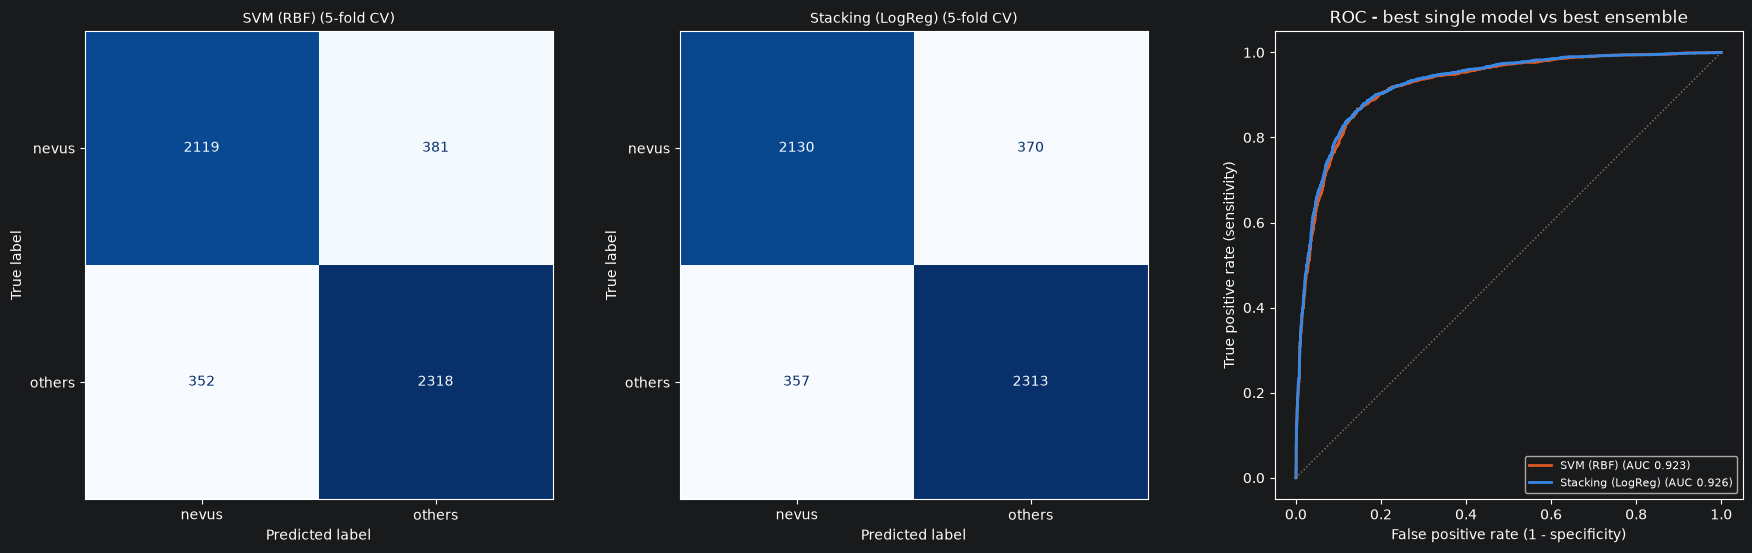

In [6]:
best_single = table_base.loc[table_base["balanced_accuracy"].idxmax(), "model"]
best_ens = table_ens.loc[table_ens["balanced_accuracy"].idxmax(), "model"]
compare = {best_single: fitted_base[best_single], best_ens: fitted_ens[best_ens]}

oof = {name: oof_predictions(model, X, y) for name, model in compare.items()}

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (name, (pred, _)) in zip(axes[:2], oof.items()):
    plot_confusion(ax, y, pred, f"{name} (5-fold CV)")
for (name, (_, scores)), color in zip(oof.items(), ["#d95926", "#3987e5"]):
    plot_roc(axes[2], y, scores, name, color)
finish_roc(axes[2], "ROC - best single model vs best ensemble")
plt.tight_layout()
plt.show()

### Diagnosing the results of ensembling

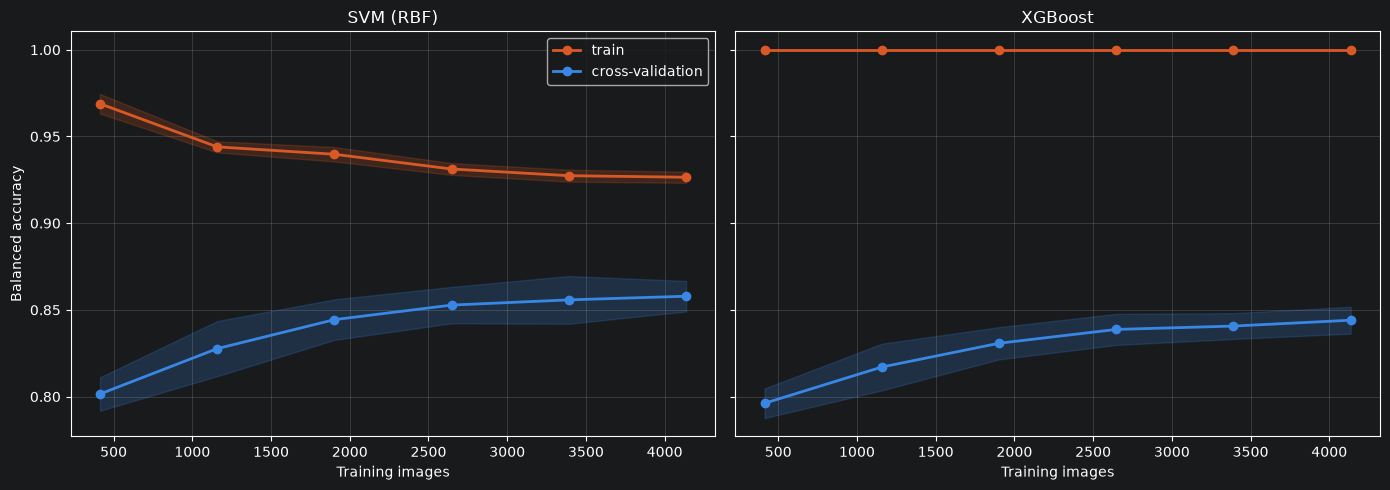

In [7]:
from sklearn.model_selection import learning_curve
from src.experiments import CV

sizes = np.linspace(0.1, 1.0, 6)
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, name in zip(axes, ["SVM (RBF)", "XGBoost"]):
    n_train, train_scores, cv_scores = learning_curve(
        fitted_base[name], X, y, cv=CV, train_sizes=sizes,
        scoring="balanced_accuracy", n_jobs=-2, shuffle=True, random_state=RANDOM_STATE)
    for scores, label, color in [(train_scores, "train", "#d95926"), (cv_scores, "cross-validation", "#3987e5")]:
        mean, std = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(n_train, mean, "o-", color=color, linewidth=2, label=label)
        ax.fill_between(n_train, mean - std, mean + std, color=color, alpha=0.2)
    ax.set_title(name)
    ax.set_xlabel("Training images")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Balanced accuracy")
axes[0].legend()
plt.tight_layout()
plt.show()

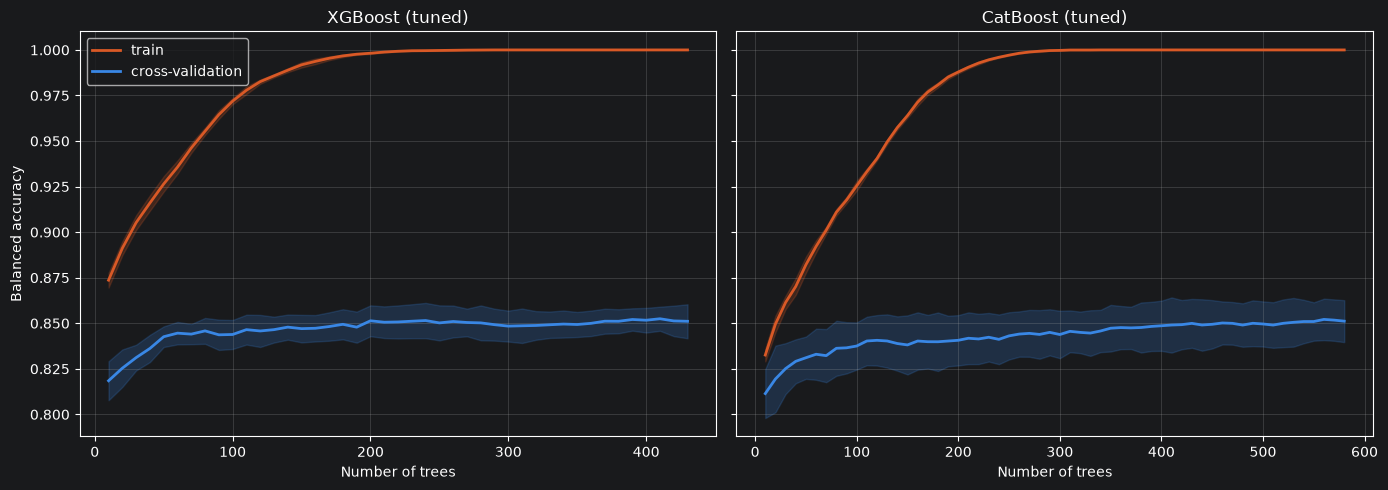

In [8]:
from sklearn.base import clone
from sklearn.metrics import balanced_accuracy_score

def iteration_curve(model, X, y, step=10):
    """Balanced accuracy on train and held-out folds after every `step` trees (XGBoost, CatBoost)."""
    curves = []
    for tr, te in CV.split(X, y):
        pipe = clone(model).fit(X[tr], y[tr])
        prep, clf = pipe[:-1], pipe[-1]                        # scaler (+selector) and the classifier
        X_tr, X_te = prep.transform(X[tr]), prep.transform(X[te])
        n_trees = clf.get_params().get("n_estimators") or clf.get_params().get("iterations")
        points = list(range(step, n_trees + 1, step))
        if hasattr(clf, "get_booster"):                       # XGBoost
            pred = lambda Z, n: clf.predict(Z, iteration_range=(0, n))
        else:                                                 # CatBoost
            pred = lambda Z, n: np.asarray(clf.predict(Z, ntree_end=n)).ravel()
        curves.append([(balanced_accuracy_score(y[tr], pred(X_tr, n)),
                        balanced_accuracy_score(y[te], pred(X_te, n))) for n in points])
    return points, np.array(curves)          # shape: folds x points x (train, cv)

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, name in zip(axes, ["XGBoost", "CatBoost"]):
    points, curves = iteration_curve(fitted_base[name], X, y)
    for k, (label, color) in enumerate([("train", "#d95926"), ("cross-validation", "#3987e5")]):
        mean, std = curves[:, :, k].mean(axis=0), curves[:, :, k].std(axis=0)
        ax.plot(points, mean, color=color, linewidth=2, label=label)
        ax.fill_between(points, mean - std, mean + std, color=color, alpha=0.2)
    ax.set_title(f"{name} (tuned)")
    ax.set_xlabel("Number of trees")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Balanced accuracy")
axes[0].legend()
plt.tight_layout()
plt.show()

In [9]:
oof_base = {name: oof_predictions(model, X, y)[0] for name, model in fitted_base.items()}
errors = pd.DataFrame({name: pred != y for name, pred in oof_base.items()})

n_wrong = errors.sum(axis=1)
print("Images misclassified by ... of the 4 best_final_models:")
print((n_wrong.value_counts().sort_index() / len(y) * 100).round(1).rename("% of images"))

# Of the images model A gets wrong, which share does model B also get wrong?
overlap = pd.DataFrame({a: {b: (errors[a] & errors[b]).sum() / errors[a].sum() for b in errors} for a in errors}).T
print("\nRow model's errors also made by column model:")
display(overlap.round(2))

Images misclassified by ... of the 4 models:
0    79.2
1     5.1
2     2.6
3     3.4
4     9.6
Name: % of images, dtype: float64

Row model's errors also made by column model:


,HistGradBoost,SVM (RBF),XGBoost,CatBoost
HistGradBoost,1.00,0.71,0.82,0.84
SVM (RBF),0.77,1.00,0.77,0.78
XGBoost,0.84,0.73,1.00,0.85
CatBoost,0.86,0.74,0.84,1.00


In [10]:
train["subtype"] = train["filename"].str.replace(r"\d+\.jpg$", "", regex=True)
hard = train[n_wrong.values == 4]

summary = pd.DataFrame({
    "hard images": hard["subtype"].value_counts(),
    "% of that subtype": (100 * hard["subtype"].value_counts() / train["subtype"].value_counts()).round(1),
}).dropna().sort_values("hard images", ascending=False)
summary

C:\Users\ferra\AppData\Local\Temp\ipykernel_9364\2469211964.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  train["subtype"] = train["filename"].str.replace(r"\d+\.jpg$", "", regex=True)


,hard images,% of that subtype
subtype,,
nev,254,10.2
mel,126,25.2
bkl,68,13.6
bcc,14,2.8
vac,14,9.3
scc,10,2.7
def,9,6.3
ack,3,0.6


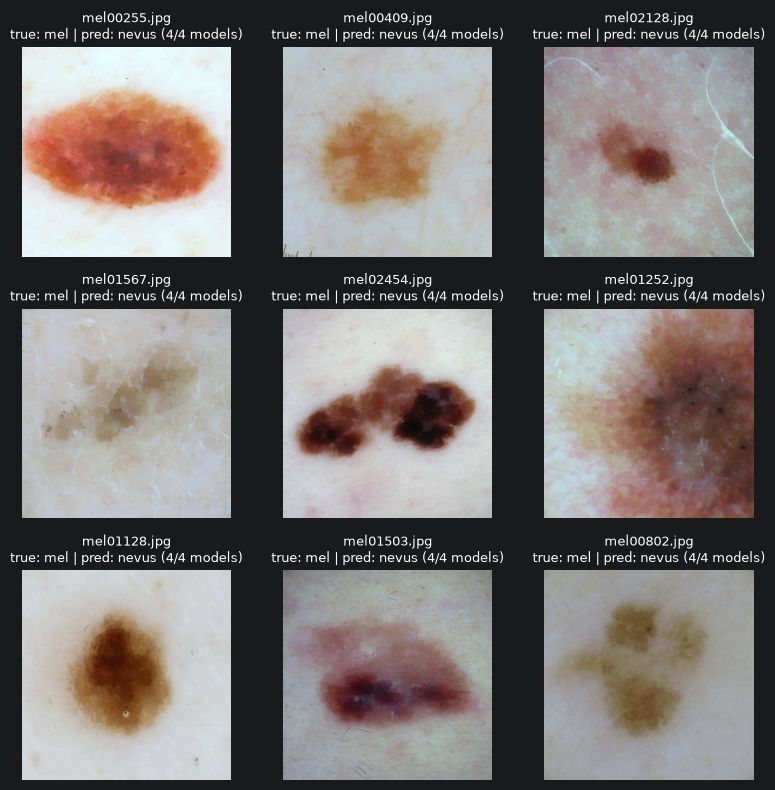

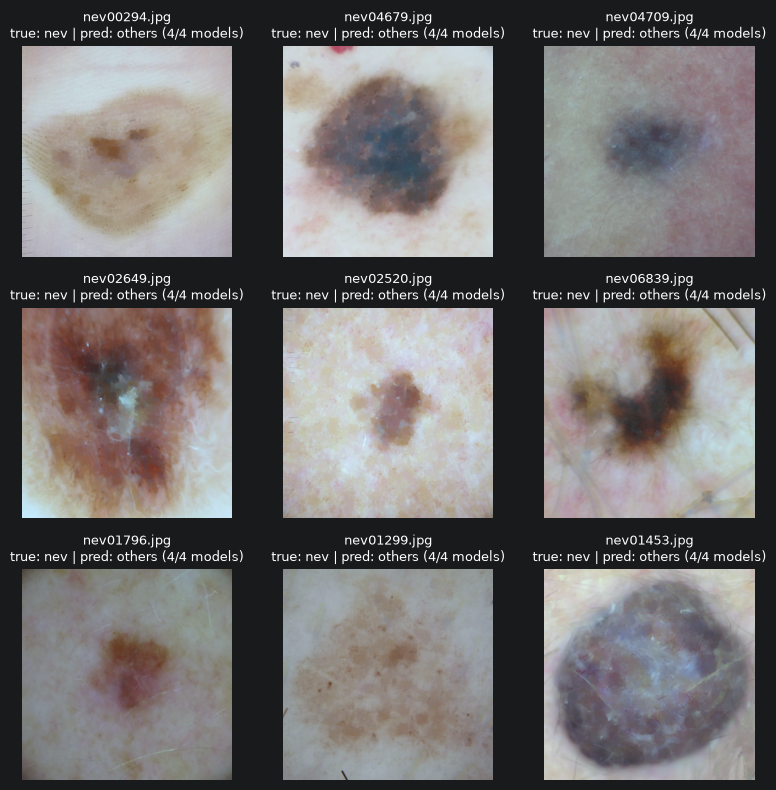

In [12]:
PRED_NAME = {0: "nevus", 1: "others"}

for sub in ["mel", "nev"]:
    s = hard[hard["subtype"] == sub].sample(9, random_state=RANDOM_STATE)
    show_grid(
        [load_preprocessed(r.filename, r.label, BINARY_PREPROC_TRAIN_DIR) for r in s.itertuples()],
        [f"{r.filename}\ntrue: {sub} | pred: {PRED_NAME[1 - r.label]} (4/4 best_final_models)" for r in s.itertuples()],
    )